# Лабораторная работа № 6

Хранение, очистка и структурирование собранных данных.

**ПМИ-2-2025. Вариант 3 — цитаты и авторы.**

Ноутбук читает сохранённый набор без запросов к сайтам. Ниже выполняются проверки очистки и контракта, полную пересборку файлов можно включить отдельным флагом.

In [1]:
from pathlib import Path
import sys, json, sqlite3, hashlib, copy
import pandas as pd
from IPython.display import display, Image

LAB_NAME = 'lab6_3'
lab = Path.cwd() if (Path.cwd()/'raw/manifest.json').exists() else Path.cwd()/LAB_NAME
assert (lab/'raw/manifest.json').is_file(), 'Откройте ноутбук из папки лабораторной или её родителя'
sys.path.insert(0, str(lab))
from src.clean import clean_rows
from src.contract import Quote
from src.rebuild import verify_raw, rebuild
from src.quality import require_mart
load_json = lambda name: json.loads((lab/name).read_text(encoding='utf-8'))
data = pd.read_parquet(lab/'clean/dataset.parquet')
display(data[['text','author','source','source_record_id','author_birth_year']].head())
display(data.dtypes.to_frame('Тип поля'))
print('Чистых цитат:', len(data), 'уникальных ключей:', data.business_key.nunique())

,text,author,source,source_record_id,author_birth_year
0,“The world as we have created it is a process ...,Albert Einstein,quotes_html,000100,1879
1,"“It is our choices, Harry, that show what we t...",J.K. Rowling,quotes_html,000101,1965
2,“There are only two ways to live your life. On...,Albert Einstein,quotes_html,000102,1879
3,"“The person, be it gentleman or lady, who has ...",Jane Austen,quotes_html,000103,1775
4,"“Imperfection is beauty, madness is genius and...",Marilyn Monroe,quotes_html,000104,1926


,Тип поля
business_key,object
text,object
author,object
author_key,object
tags,object
source,object
source_url,object
parser_version,object
collected_at,"datetime64[ns, UTC]"
source_record_id,string[python]


Чистых цитат: 420 уникальных ключей: 420


## 1. Источники и неизменность raw

100 HTML-цитат из сохранённого снимка лабораторной № 5 и 320 записей дополнительного API DummyJSON. API лабораторной № 3 был Open Library. Учебные дефекты помечены отдельно, сведения источников не дополняются выдуманными тегами.

In [2]:
raw = []
for path in sorted((lab/'raw').glob('*.jsonl')):
    raw.extend(json.loads(line) for line in path.read_text(encoding='utf-8').splitlines() if line.strip())
raw_hashes = verify_raw()
required = {'_source','_source_url','_collected_at','_parser_version','_status'}
assert all(required <= r.keys() for r in raw)
print('Исходных строк:',len(raw),'учебных дефектов:',sum(bool(r.get('_synthetic')) for r in raw))
display(pd.DataFrame(raw)[['_source','_source_url','_collected_at','_parser_version','_status']].head())
print('SHA-256 всех raw файлов:',raw_hashes)

Исходных строк: 452 учебных дефектов: 32


,_source,_source_url,_collected_at,_parser_version,_status
0,dummyjson_api,https://dummyjson.com/quotes?limit=80&skip=0,2026-10-14T22:29:18.637333+00:00,quotes-api-import/1.0,200
1,dummyjson_api,https://dummyjson.com/quotes?limit=80&skip=0,2026-10-14T22:29:18.637333+00:00,quotes-api-import/1.0,200
2,dummyjson_api,https://dummyjson.com/quotes?limit=80&skip=0,2026-10-14T22:29:18.637333+00:00,quotes-api-import/1.0,200
3,dummyjson_api,https://dummyjson.com/quotes?limit=80&skip=0,2026-10-14T22:29:18.637333+00:00,quotes-api-import/1.0,200
4,dummyjson_api,https://dummyjson.com/quotes?limit=80&skip=0,2026-10-14T22:29:18.637333+00:00,quotes-api-import/1.0,200


SHA-256 всех raw файлов: {'api_quotes.jsonl': 'c586bfca155c02e05ad87159cc78888aa1ce47ef968c2b25304b0b3202578f64', 'html_quotes.jsonl': '67f8091dee7f10157984356cd2e3f842bd54c2444d04737971434b50678979df', 'synthetic_cases.jsonl': 'e33417230c40b76cc3acae8308de71473bd33fdf220fff0af6303fb42ecb9eac'}


## 2. Очистка и пересборка без сети

Шаги: текст → ключ → типы → пропуски → группы дублей → бизнес-правила. Последний этап выбирает свежую валидную запись, сохраняя причины брака альтернатив. Таблица этапа 5 считает группы, а окончательное распределение считает каждую исходную строку ровно один раз.

In [3]:
duplicates, accepted = [], []
rebuilt, rejects, protocol = clean_rows(raw, duplicates=duplicates, accepted_indices=accepted)
assert {r['business_key'] for r in rebuilt} == set(data.business_key)
assert len(rebuilt) == len(data) >= 300
assert verify_raw() == raw_hashes
display(pd.DataFrame(protocol))
rejected_indices = {r['raw_index'] for r in rejects}
valid_duplicates = {r['raw_index'] for r in duplicates if r['status']=='duplicate'}
assert not (set(accepted)&rejected_indices or set(accepted)&valid_duplicates or rejected_indices&valid_duplicates)
assert set(accepted)|rejected_indices|valid_duplicates == set(range(len(raw)))
print('Баланс:',len(raw),'=',len(accepted),'принято +',len(rejected_indices),'брак +',len(valid_duplicates),'дубли')
display(pd.DataFrame(rejects).groupby(['stage','field','reason']).size().rename('Записей').reset_index())

,step,before,after,changed,removed,note
0,1. Нормализация текста,452,452,17,0,"NFKC, NBSP, zero-width, пробелы"
1,2. Бизнес-ключ и URL,452,452,452,0,SHA(source|source_id); tracking-URL: 8
2,3. Типизация,452,446,446,6,"UTC, числовой год, строковый ID; ошибки в rejects"
3,4. Пропуски,446,434,0,12,"Текст, автор и URL обязательны; неизвестный го..."
4,"5. Полные, ключевые и почти-дубли",434,420,0,14,Сформированы группы; альтернативы отложены до ...
5,6. Бизнес-правила и контракт,420,420,420,0,Контракт всех кандидатов; fallback=6; невалидн...


Баланс: 452 = 420 принято + 24 брак + 8 дубли


,stage,field,reason,Записей
0,3,collected_at / author_birth_year,Invalid isoformat string: 'invalid-date',6
1,4,author_raw,Отсутствует обязательное поле,6
2,4,text_raw,Отсутствует обязательное поле,6
3,6,tags,"Value error, Тег должен быть непустым slug в н...",6


In [4]:
RUN_REBUILD = False  # True пересоздаёт производные clean/БД/mart только из локального raw
if RUN_REBUILD:
    print(rebuild())
else:
    display(pd.Series(load_json('clean/rebuild_summary.json')).to_frame('Сохранённый результат'))

,Сохранённый результат
duplicates,14
raw_rows,452
clean_rows,420
authors,101
tag_links,232
rejected_rows,24
quality,green
raw_unchanged,True
load,"{'rows': 420, 'total_rows': 420, 'inactive': 0..."
duration_s,0.8143


## 3. Сравнение CSV, JSONL и Parquet

Измерен один набор без размножения, медиана семи чтений с прогретым файловым кэшем. JSONL для выбора столбцов всё равно разбирается целиком. Ведущий ноль исчезает при автоматическом выводе типов читателем, а не при записи JSON-строки.

In [5]:
display(pd.read_csv(lab/'clean/format_benchmark.csv'))
display(pd.DataFrame(load_json('clean/format_types.json')))
print('ID в Parquet:',repr(data.source_record_id.iloc[0]))
print('Результат обратного чтения с явными типами:')
display(load_json('clean/format_roundtrip.json'))

,format,bytes,read_all_ms,read_three_ms,date_dtype,id_dtype,id_example
0,CSV,140071,2.8125,2.0254,object,int64,100
1,JSONL,215575,5.9160,6.1048,"datetime64[ns, UTC]",int64,100
2,Parquet,74376,2.6624,1.8352,"datetime64[ns, UTC]",string,100


,CSV,JSONL,Parquet
business_key,object,object,object
text,object,object,object
author,object,object,object
author_key,object,object,object
tags,object,object,object
source,object,object,object
source_url,object,object,object
parser_version,object,object,object
collected_at,object,"datetime64[ns, UTC]","datetime64[ns, UTC]"
source_record_id,int64,int64,string


ID в Parquet: '000100'
Результат обратного чтения с явными типами:


{'rows': 420,
 'columns': ['business_key',
  'text',
  'author',
  'author_key',
  'tags',
  'source',
  'source_url',
  'parser_version',
  'collected_at',
  'source_record_id',
  'text_length',
  'author_birth_year'],
 'all_values_equal_with_explicit_types': True,
 'leading_zero_example': '000100',
 'date_example_utc': '2026-10-14T22:29:22.355826+00:00'}

## 4. Контракт и ошибки

Quote задаёт диапазоны, обязательность, три field_validator и model_validator. Ключ цитаты должен соответствовать source/id, ключ автора — имени, длина — фактическому числу символов, домен — источнику. Невалидные данные сохраняются с полем, причиной и payload.

In [6]:
for record in rebuilt:
    Quote.model_validate(record)
display(pd.DataFrame(load_json('clean/contract_examples.json')))
print('Все',len(rebuilt),'итоговых записей прошли контракт')

,check,result,message
0,Пустой текст,rejected,String should have at least 8 characters
1,Короткое имя,rejected,String should have at least 2 characters
2,Неверный тег,rejected,"Value error, Тег должен быть непустым slug в н..."
3,Дата без зоны,rejected,"Value error, Нужен часовой пояс UTC"
4,Неверный ключ,rejected,"Value error, Бизнес-ключ не соответствует исто..."
5,Неверная длина,rejected,Input should be greater than 7
6,Неверный источник URL,rejected,"Value error, URL не соответствует источнику"


Все 420 итоговых записей прошли контракт


## 5. БД, UPSERT и история

Основная warehouse.db сохраняет исходный чистый набор. Демонстрация A/B/C работает отдельно и в C меняет теги только двух цитат. Снимки истории записываются при изменении содержимого, идентичный повтор сохраняет updated_at. Загрузка принимает полный снимок, отсутствующие ключи остаются неактивными, SQL-представления выбирают только is_active=1.

In [7]:
demo = load_json('clean/idempotency.json')
display(pd.DataFrame(demo['runs']))
assert demo['updated_at_preserved'] and len(demo['changed_keys'])==2
display(pd.DataFrame(demo['constraints']))
with sqlite3.connect(f'file:{(lab/"db/warehouse.db").as_posix()}?mode=ro',uri=True) as db:
    assert db.execute('PRAGMA foreign_key_check').fetchall()==[]
    display(pd.read_sql_query('SELECT * FROM quotes_by_source',db))
    print('История основной БД:',db.execute('SELECT COUNT(*) FROM quote_history').fetchone()[0])

,run,rows,total_rows,inactive,deactivated,inserted,updated,unchanged,history
0,A,420,420,0,0,420,0,0,420
1,B,420,420,0,0,0,0,420,420
2,C,420,420,0,0,0,2,418,422


,check,result,message
0,duplicate_key,rejected,UNIQUE constraint failed: quotes.business_key
1,check,rejected,CHECK constraint failed: text_length BETWEEN 8...
2,not_null,rejected,NOT NULL constraint failed: quotes.text


,source,quotes,mean_length
0,dummyjson_api,320,79.44
1,quotes_html,100,122.27


История основной БД: 420


## 6. Метрики качества и красный светофор

Полнота обязательных и необязательных полей, уникальность, валидность raw, доля брака с причинами, согласованность, возраст и стабильность объёма. Первый запуск явно помечен как bootstrap, повтор сравнивается с фактическим предыдущим. Метрики отражают момент сохранённой оценки.

In [8]:
quality = load_json('clean/quality.json')
display(pd.DataFrame(quality['metrics']))
print('Вердикт:',quality['verdict'],'валидность:',quality['contract_valid_raw'],'/',quality['raw_rows'])
print('Причины отбраковки:',quality['reject_reasons'])
print('Первая оценка объёма:',load_json('clean/quality_bootstrap.json').get('previous_rows'))
hash_mart = lambda: {str(p.relative_to(lab)):hashlib.sha256(p.read_bytes()).hexdigest() for p in (lab/'mart').rglob('*') if p.is_file()}
before = hash_mart()
forced = copy.deepcopy(quality)
forced['metrics'][0]['status']='red'
try:
    require_mart(forced)
except RuntimeError as error:
    print('Красный статус остановил mart:',error)
else:
    raise AssertionError('Красный статус не остановил mart')
assert before == hash_mart()
display(load_json('clean/red_gate_evidence.json'))

,metric,value,green,yellow,direction,status,reason
0,mandatory_completeness,1.000000,1.0,0.99,min,green,Обязательные поля нужны для загрузки
1,optional_completeness,0.238095,0.1,0.05,min,green,Год рождения доступен у части HTML-авторов
2,unique_keys,1.000000,1.0,0.99,min,green,Уникальный бизнес-ключ
3,validity,0.946903,0.9,0.80,min,green,До 10% явно внесённых дефектов
4,reject_share,0.053097,0.1,0.20,max,green,До 10% учебной отбраковки
5,business_consistency,1.000000,1.0,0.99,min,green,Полный контракт и согласованность полей
6,median_age_days,12.835032,30.0,60.00,max,green,Для учебных метаданных допустим возраст до месяца
7,volume_change,0.000000,0.1,0.20,max,green,Изменение объёма до 10%


Вердикт: green валидность: 428 / 452
Причины отбраковки: {"Invalid isoformat string: 'invalid-date'": 6, 'Отсутствует обязательное поле': 12, 'Value error, Тег должен быть непустым slug в нижнем регистре': 6}
Первая оценка объёма: None
Красный статус остановил mart: Mart не обновлён: красные метрики: mandatory_completeness


{'exit_code': 2,
 'message': 'Mart не обновлён: красные метрики: mandatory_completeness',
 'mart_files': 6,
 'mart_hashes_unchanged': True}

## 7. Представления, партиции и два графика

SQL-агрегаты экспортируются в Parquet. Снимки разделены по дате сбора, чтение одной партиции использует фильтр. График дат отражает распределение архивных наблюдений и учебных копий, а не изменение цитат во времени.

quotes_by_author


,name,quotes,mean_length
0,Rumi,56,80.46
1,Muhammad Ali,41,102.12
2,Ali ibn Abi Talib (R.A),25,84.76
3,Abdul Kalam,22,112.05
4,Mark Twain,18,74.50
5,Albert Einstein,18,86.94
6,Abu Bakr (R.A),15,68.13
7,Umar ibn Al-Khattāb (R.A),14,69.86


quotes_by_source


,source,quotes,mean_length
0,dummyjson_api,320,79.44
1,quotes_html,100,122.27


popular_tags


,tag,quotes
0,love,14
1,inspirational,13
2,life,13
3,humor,12
4,books,11
5,reading,7
6,friendship,5
7,friends,4


Только партиция 2026-10-07 : 92 строки
Во всех партициях: 420 строк, дубликатов нет


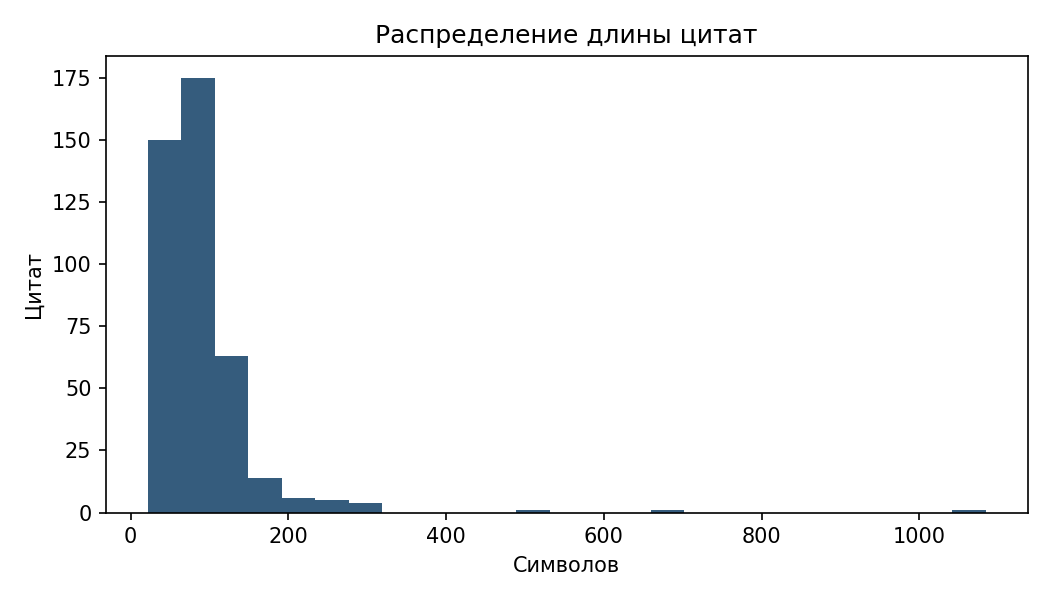

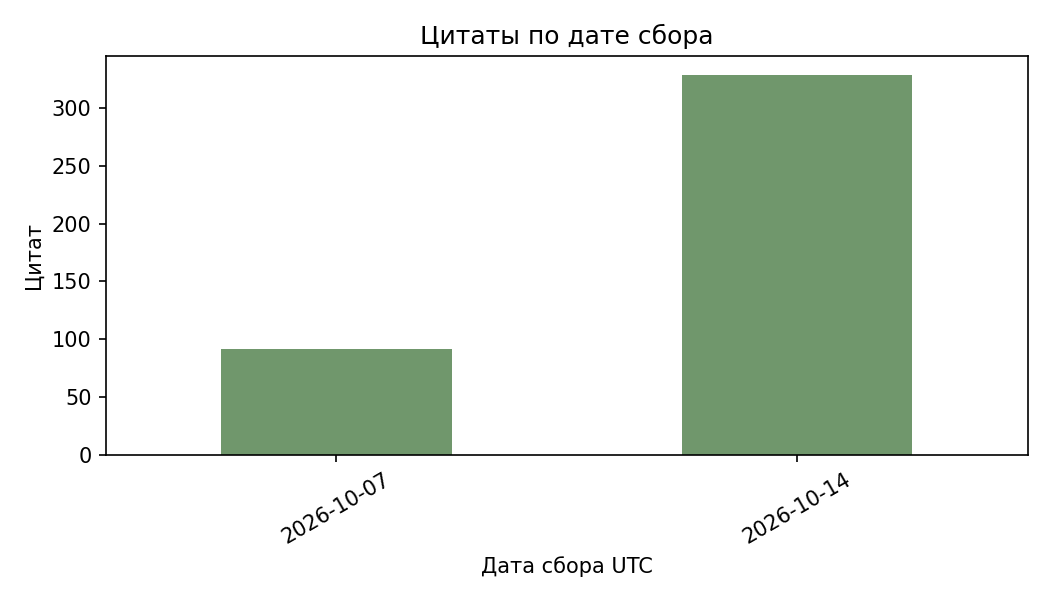

In [9]:
for name in ('quotes_by_author','quotes_by_source','popular_tags'):
    print(name)
    display(pd.read_parquet(lab/'mart/views'/f'{name}.parquet').head(8))
partition = load_json('mart/partition_read.json')
selected = partition['selected'].split('=',1)[1]
one = pd.read_parquet(lab/'mart/snapshots',filters=[('dt','=',selected)])
assert len(one)==partition['rows']
print('Только партиция',selected,':',len(one),'строки')
snapshot = pd.read_parquet(lab/'mart/snapshots')
assert len(snapshot)==len(data) and snapshot.business_key.nunique()==len(data)
print('Во всех партициях:',len(snapshot),'строк, дубликатов нет')
display(Image(filename=str(lab/'figures/length_distribution.png')))
display(Image(filename=str(lab/'figures/collection_timeline.png')))

## 8. n8n и сверка с Python

Workflow нормализует поля, считает ключ, разделяет валидные и дефектные данные и удаляет дубли. CSV записывает сам n8n. В этом экспорте нет операции UPSERT, полной pydantic-модели, истории и светофора. Расписание задано, но экспортированный workflow неактивен.

In [10]:
nocode = pd.read_csv(lab/'nocode/nocode_result.csv',dtype=str).fillna('')
bad = pd.read_csv(lab/'nocode/rejects.csv',dtype=str).fillna('')
assert len(nocode)>=30 and nocode.business_key.is_unique
joined=nocode.merge(data,on='business_key',suffixes=('_n8n','_python'),validate='one_to_one')
assert len(joined)==len(nocode)
for field in ('text','author'):
    assert joined[field+'_n8n'].eq(joined[field+'_python']).all()
print('n8n:',len(nocode),'принято;',len(bad),'брак. Ключи, текст и автор совпали с Python')
display(nocode[['text','author','source']].head())
display(bad)
display(load_json('nocode/metrics.json'))

n8n: 34 принято; 3 брак. Ключи, текст и автор совпали с Python


,text,author,source
0,“The world as we have created it is a process ...,Albert Einstein,quotes_html
1,"“It is our choices, Harry, that show what we t...",J.K. Rowling,quotes_html
2,“There are only two ways to live your life. On...,Albert Einstein,quotes_html
3,"“The person, be it gentleman or lady, who has ...",Jane Austen,quotes_html
4,"“Imperfection is beauty, madness is genius and...",Marilyn Monroe,quotes_html


,text,author,tags,source,source_url,source_record_id,collected_at,hash_input,valid,reason,business_key
0,,Albert Einstein,"[""change"",""deep-thoughts"",""thinking"",""world""]",quotes_html,https://quotes.toscrape.com/page/1/,000100,2026-10-07T15:19:44.701Z,quotes_html|000100,FALSE,text: длина вне диапазона,95191512e7a92c6140fad9eb30abc268859493a813ad73...
1,“The world as we have created it is a process ...,,"[""change"",""deep-thoughts"",""thinking"",""world""]",quotes_html,https://quotes.toscrape.com/page/1/,000100,2026-10-07T15:19:44.701Z,quotes_html|000100,FALSE,author: пустое или короткое имя,95191512e7a92c6140fad9eb30abc268859493a813ad73...
2,“The world as we have created it is a process ...,Albert Einstein,"[""change"",""deep-thoughts"",""thinking"",""world""]",quotes_html,https://quotes.toscrape.com/page/1/,000100,,quotes_html|000100,FALSE,collected_at: неверная дата,95191512e7a92c6140fad9eb30abc268859493a813ad73...


{'workflow_id': 'Lab6QuotesVariant3',
 'n8n_version': '1.121.3',
 'status': 'success (UI; CLI finished=true and all node executionStatus=success)',
 'input_records': 39,
 'valid_before_deduplication': 36,
 'duplicates_removed': 2,
 'valid_output': 34,
 'rejects': 3,
 'business_key': 'SHA256(source + "|" + source_record_id), UTF-8',
 'timezone': 'Asia/Yekaterinburg',
 'schedule': '0 8 * * *',
 'active': False,
 'repeat_run': 'both finished; CSV binary outputs identical; unique business_key verified',
 'first_run_started_at': '2026-10-27T18:29:48.870Z',
 'first_run_stopped_at': '2026-10-27T18:29:49.828Z',
 'second_run_started_at': '2026-10-27T18:29:55.847Z',
 'second_run_stopped_at': '2026-10-27T18:29:56.803Z',
 'cli_raw_status': 'running',
 'node_runs': {'Manual start': 1,
  'Read source snapshot': 1,
  'Parse JSON': 1,
  'Split records': 1,
  'Normalize fields': 1,
  'Business key': 1,
  'Valid record': 1,
  'Remove duplicates': 1,
  'Select output fields': 1,
  'CSV': 1,
  'Save CSV':

## 9. Вывод и правовая оценка

Сырые снимки позволяют восстановить 420 цитат без сети. Повторная загрузка не создаёт дубли, две учебные правки дают две записи истории. Протокол и непересекающееся распределение объясняют судьбу всех 452 исходных строк. CSV удобен для обмена, Parquet сохраняет типы, SQLite проверяет ограничения и историю. Полный контроль качества в этой работе реализован в Python, выбранный n8n-сценарий выполняет частичный экспорт.

Имена и годы рождения могут относиться к персональным данным, хэши имён не являются обезличиванием. Открытая страница не устанавливает основание обработки или право распространения. Комплект предназначен для локальной сдачи, предлагаемый срок хранения — до 30 дней после проверки. Подробная оценка 152-ФЗ/GDPR, ограничения и ссылки приведены в [report.md](report.md).